In [ ]:
!nvidia-smi

Mon Oct 12 08:28:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
import urllib.request

categories = [
    "airplane",
    "car",
    "cat",
    "fish",
    "flower",
    "house",
    "sun",
    "tree"
]

os.makedirs("quickdraw_data", exist_ok=True)

for category in categories:
    url = (
        "https://storage.googleapis.com/quickdraw_dataset/"
        f"full/numpy_bitmap/{category}.npy"
    )
    destination = f"quickdraw_data/{category}.npy"

    print(f"Téléchargement de : {category}...")
    urllib.request.urlretrieve(url, destination)

print("Téléchargement terminé.")
print("Catégories téléchargées :", ", ".join(categories))

Téléchargement de : airplane...
Téléchargement de : car...
Téléchargement de : cat...
Téléchargement de : fish...
Téléchargement de : flower...
Téléchargement de : house...
Téléchargement de : sun...
Téléchargement de : tree...
Téléchargement terminé.
Catégories téléchargées : airplane, car, cat, fish, flower, house, sun, tree


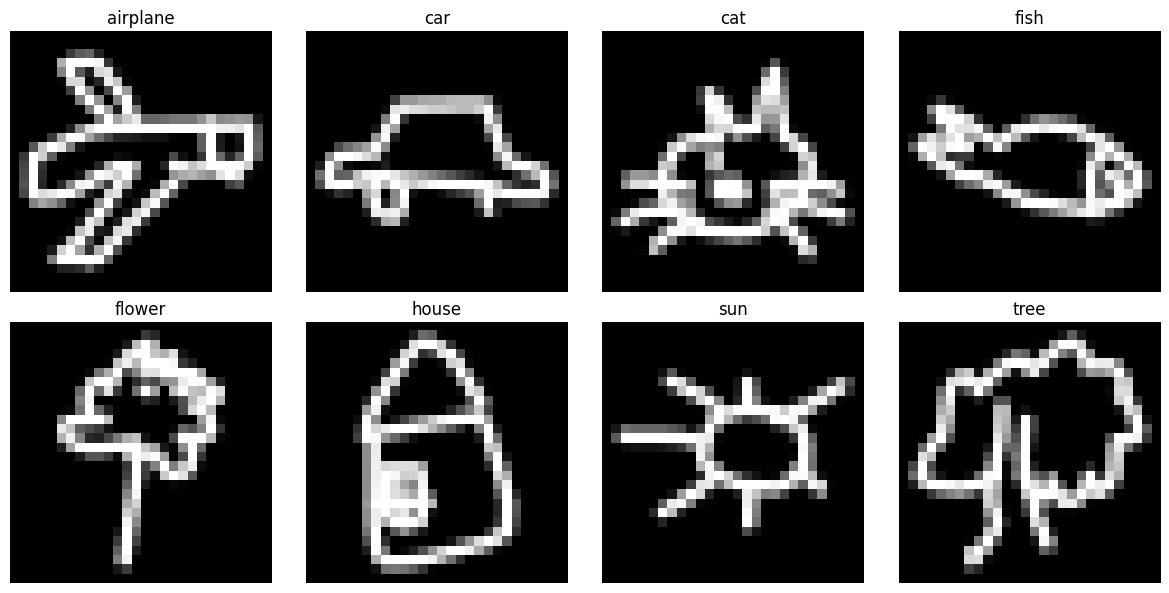

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

categories = [
    "airplane", "car", "cat", "fish",
    "flower", "house", "sun", "tree"
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, category in zip(axes.ravel(), categories):
    drawings = np.load(f"quickdraw_data/{category}.npy")

    ax.imshow(drawings[0].reshape(28, 28), cmap="gray")
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

NameError: name 'X' is not defined

In [ ]:
import shutil
import os

if os.path.exists("quickdraw_data"):
    shutil.rmtree("quickdraw_data")
    print("Ancien dossier supprimé.")
else:
    print("Le dossier quickdraw_data n'existe pas encore.")

Ancien dossier supprimé.


In [ ]:
import os, urllib.request, numpy as np

CLASSES = ['airplane', 'car', 'cat', 'fish', 'flower', 'house', 'sun', 'tree']
NB = 10000   # images par catégorie
os.makedirs('data', exist_ok=True)
X, y = [], []
for i, c in enumerate(CLASSES):
    chemin = f'data/{c}.npy'
    if not os.path.exists(chemin):
        url = f'https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{c}.npy'
        urllib.request.urlretrieve(url, chemin)
    d = np.load(chemin)[:NB]
    X.append(d)
    y.append(np.full(len(d), i))
X = np.concatenate(X).reshape(-1, 1, 28, 28).astype('float32') / 255.0
y = np.concatenate(y).astype('int64')
print(X.shape, y.shape)

(80000, 1, 28, 28) (80000,)


In [ ]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

In [ ]:
import torch, torch.nn as nn

dev = 'cuda' if torch.cuda.is_available() else 'cpu'

class CNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, n))
    def forward(self, x):
        return self.net(x)

model = CNN(len(CLASSES)).to(dev)
opt = torch.optim.Adam(model.parameters(), 1e-3)
perte = nn.CrossEntropyLoss()
Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)
Xte_t, yte_t = torch.tensor(Xte), torch.tensor(yte)
historique = []

for ep in range(8):
    model.train()
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 128):
        idx = perm[i:i + 128]
        xb, yb = Xtr_t[idx].to(dev), ytr_t[idx].to(dev)
        opt.zero_grad()
        l = perte(model(xb), yb)
        l.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(Xte_t[i:i + 1000].to(dev)).argmax(1).cpu()
                          for i in range(0, len(Xte_t), 1000)])
    precision = (pred == yte_t).float().mean().item()
    historique.append(precision)
    print('Epoque', ep + 1, 'précision test :', precision)

Epoque 1 précision test : 0.9129375219345093
Epoque 2 précision test : 0.9301249980926514
Epoque 3 précision test : 0.9365000128746033
Epoque 4 précision test : 0.9417499899864197
Epoque 5 précision test : 0.9430000185966492
Epoque 6 précision test : 0.945437490940094
Epoque 7 précision test : 0.9476875066757202
Epoque 8 précision test : 0.9465000033378601


              precision    recall  f1-score   support

    airplane       0.90      0.95      0.93      2000
         car       0.98      0.95      0.96      2000
         cat       0.92      0.91      0.92      2000
        fish       0.94      0.94      0.94      2000
      flower       0.93      0.94      0.93      2000
       house       0.98      0.98      0.98      2000
         sun       0.97      0.96      0.97      2000
        tree       0.95      0.94      0.95      2000

    accuracy                           0.95     16000
   macro avg       0.95      0.95      0.95     16000
weighted avg       0.95      0.95      0.95     16000

[[1909    4   30   26   11    3    6   11]
 [  36 1897   22   21    8    8    3    5]
 [  56    6 1818   35   30    9   25   21]
 [  64   12   25 1874    9    3    9    4]
 [  31    4   22   11 1871    4    6   51]
 [   5    4   11    5    4 1965    4    2]
 [   9    2   28   10   11    7 1926    7]
 [  11    5   12    2   65   12    9 1884]]


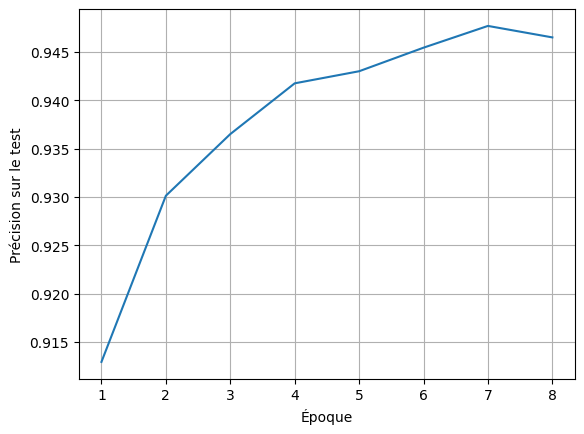

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
print(classification_report(yte, pred.numpy(), target_names=CLASSES))
print(confusion_matrix(yte, pred.numpy()))
plt.plot(range(1, len(historique) + 1), historique)
plt.xlabel('Époque'); plt.ylabel('Précision sur le test'); plt.grid(True); plt.show()

In [ ]:
!pip install onnx
model.eval().cpu()
torch.onnx.export(model, torch.zeros(1, 1, 28, 28), 'ai_sketch.onnx',
                  input_names=['input'], output_names=['output'],
                  opset_version=13, dynamo=False)

import cv2
net = cv2.dnn.readNetFromONNX('ai_sketch.onnx')
resultats = []
for img in Xte[:10]:
    net.setInput(img.reshape(1, 1, 28, 28))
    resultats.append(int(net.forward()[0].argmax()))
print(resultats)
print(list(yte[:10]))

from google.colab import files
files.download('ai_sketch.onnx')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 25.7 MB/s eta 0:00:00


/tmp/ipykernel_527/2434484439.py:3: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1, 1, 28, 28), 'ai_sketch.onnx',


[3, 7, 1, 7, 6, 1, 1, 4, 1, 7]
[np.int64(3), np.int64(7), np.int64(1), np.int64(7), np.int64(6), np.int64(1), np.int64(1), np.int64(7), np.int64(1), np.int64(7)]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2
import numpy as np

CLASSES = ['airplane', 'car', 'cat', 'fish', 'flower', 'house', 'sun', 'tree']
NOMS_FR = {'airplane': 'avion', 'car': 'voiture', 'cat': 'chat', 'fish': 'poisson',
           'flower': 'fleur', 'house': 'maison', 'sun': 'soleil', 'tree': 'arbre'}

def preparer(gris):
    # gris : image en niveaux de gris, dessin foncé sur fond blanc
    masque = (gris < 250).astype(np.uint8) * 255
    pts = cv2.findNonZero(masque)
    if pts is None:
        return None
    x, y, w, h = cv2.boundingRect(pts)
    crop = masque[y:y + h, x:x + w]
    cote = max(w, h)
    marge = int(cote * 0.17) + 1
    taille = cote + 2 * marge
    carre = np.zeros((taille, taille), np.uint8)
    oy, ox = (taille - h) // 2, (taille - w) // 2
    carre[oy:oy + h, ox:ox + w] = crop
    k = max(1, cote // 28)            # épaissit les traits trop fins après réduction
    carre = cv2.dilate(carre, np.ones((k, k), np.uint8))
    return cv2.resize(carre, (28, 28), interpolation=cv2.INTER_AREA)

FileNotFoundError: [Errno 2] No such file or directory: 'quickdraw_data/airplane.npy'

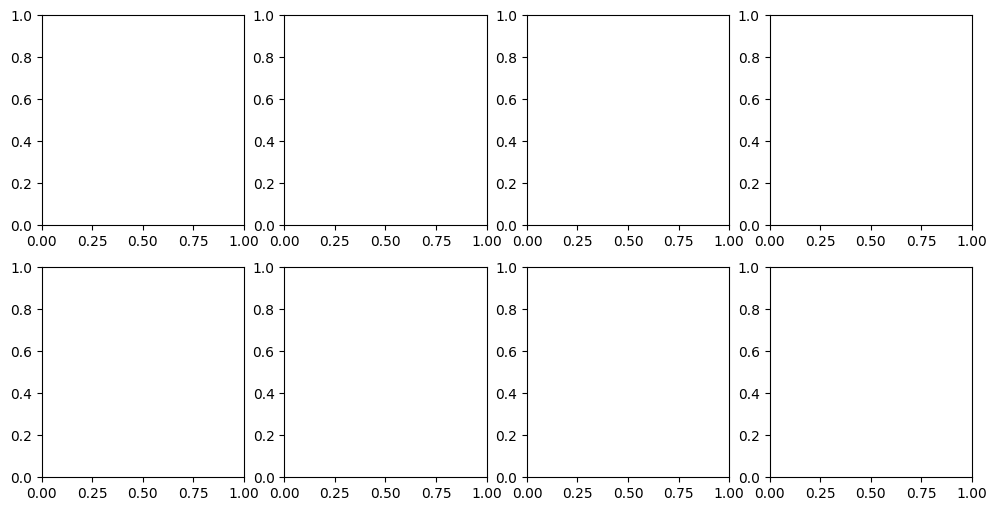

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

categories = [
    "airplane", "car", "cat", "fish",
    "flower", "house", "sun", "tree"
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, category in zip(axes.ravel(), categories):
    chemin = f"quickdraw_data/{category}.npy"

    dessins = np.load(chemin)
    image = dessins[0].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

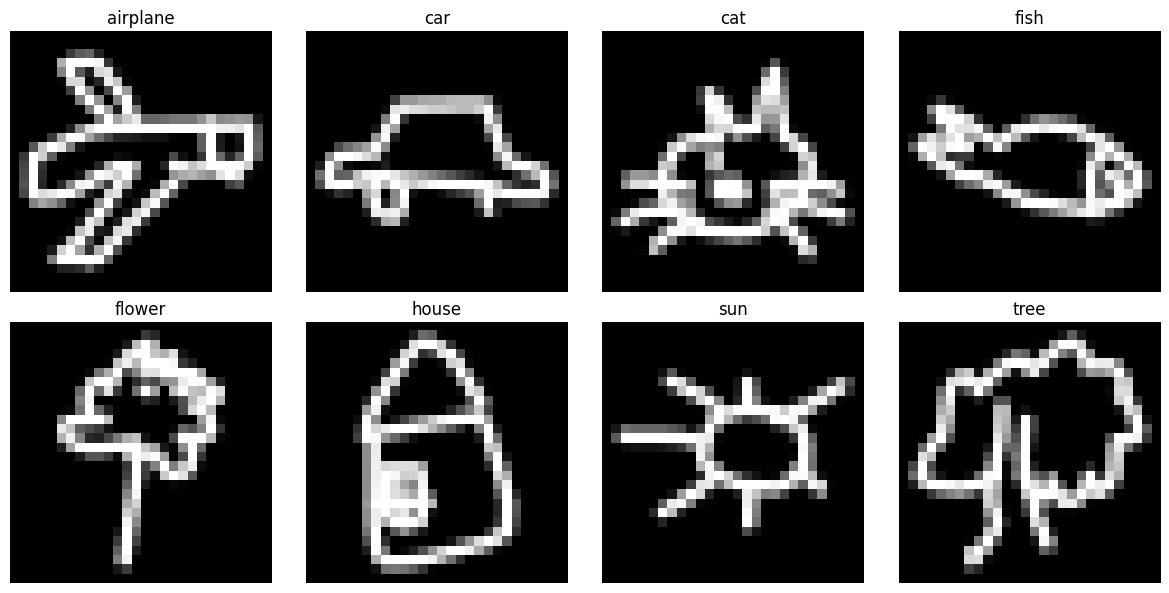

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

categories = [
    "airplane", "car", "cat", "fish",
    "flower", "house", "sun", "tree"
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, category in zip(axes.ravel(), categories):
    chemin = f"data/{category}.npy"

    dessins = np.load(chemin)
    image = dessins[0].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

files.upload()

Saving ai_sketch.onnx to ai_sketch.onnx


{'ai_sketch.onnx': b'\x08\x07\x12\x07pytorch\x1a\x062.11.0:\x96\xfdf\n\xb0\x01\n\x05input\n\x0cnet.0.weight\n\nnet.0.bias\x12\x18/net/net.0/Conv_output_0\x1a\x0f/net/net.0/Conv"\x04Conv*\x12\n\tdilations@\x01@\x01\xa0\x01\x07*\x0c\n\x05group\x18\x01\xa0\x01\x02*\x15\n\x0ckernel_shape@\x03@\x03\xa0\x01\x07*\x11\n\x04pads@\x01@\x01@\x01@\x01\xa0\x01\x07*\x10\n\x07strides@\x01@\x01\xa0\x01\x07\nK\n\x18/net/net.0/Conv_output_0\x12\x18/net/net.1/Relu_output_0\x1a\x0f/net/net.1/Relu"\x04Relu\n\xb6\x01\n\x18/net/net.1/Relu_output_0\x12\x1b/net/net.2/MaxPool_output_0\x1a\x12/net/net.2/MaxPool"\x07MaxPool*\x10\n\tceil_mode\x18\x00\xa0\x01\x02*\x12\n\tdilations@\x01@\x01\xa0\x01\x07*\x15\n\x0ckernel_shape@\x02@\x02\xa0\x01\x07*\x11\n\x04pads@\x00@\x00@\x00@\x00\xa0\x01\x07*\x10\n\x07strides@\x02@\x02\xa0\x01\x07\n\xc6\x01\n\x1b/net/net.2/MaxPool_output_0\n\x0cnet.3.weight\n\nnet.3.bias\x12\x18/net/net.3/Conv_output_0\x1a\x0f/net/net.3/Conv"\x04Conv*\x12\n\tdilations@\x01@\x01\xa0\x01\x07*\x0c\n\